# 02c · Train KAN + TopK with 32 active features

**Choose a T4 or larger GPU, connect the same Drive account, and select Runtime → Run all.** This reuses the activation files and split from notebook 02. You do not need to rerun GraphCast or finish notebook 02b first.

The model learns 4,096 cubic spline features, then keeps at most **32 largest absolute activations per mesh node**, preserving signs. It is a separate experiment from both the original TopK SAE and the L1 KAN-SAE.

The default 20 epochs include one dense warm-up epoch to start the zero-initialized splines learning, followed by 19 epochs with the TopK gate. There is no L1 penalty. An auxiliary reconstruction loss helps unused features learn. Validation always uses the 32-feature gate, and only sparse-training epochs can become `best.pt`.

Results are saved separately in `kan_topk_runs/kan_topk_k32`. Improvement in cyclone F1 must be measured in notebook 04; it is not assumed.


## Step 1 — Connect Drive and load the shared project code

In [1]:
# @title Connect Drive and load the project
import json
from google.colab import drive

import os
import subprocess
import sys
from pathlib import Path

# Notebooks 02c, 04 and 05 share this immutable code version.
RELEASE = 'ddbc28bfbd8e74e4791e15253d3a504b1c745d4b'
REPO = Path('/content') / ('ams691_project_' + RELEASE[:12])
if not (REPO / '.git').is_dir():
    subprocess.run(['git', 'init', '-q', str(REPO)], check=True)
head = subprocess.run(['git', '-C', str(REPO), 'rev-parse', '--verify', 'HEAD'],
                      capture_output=True, text=True)
if head.stdout.strip() != RELEASE:
    subprocess.run(['git', '-C', str(REPO), 'fetch', '-q', '--depth', '1',
                    'https://github.com/observerhan/graphcast-interpretability.git', RELEASE], check=True)
    subprocess.run(['git', '-C', str(REPO), 'checkout', '-q', '--detach', RELEASE], check=True)
sys.path.insert(0, str(REPO / 'scripts'))
sys.path.insert(0, str(REPO / 'src'))

drive.mount('/content/drive')
DRIVE_PROJECT = Path('/content/drive/MyDrive/AMS691_GraphCast')

Mounted at /content/drive


## Step 2 — Training settings

Keep the defaults for the first experiment. `EPOCHS` includes the dense warm-up; it must exceed `WARMUP_EPOCHS`. Increase only `EPOCHS` to continue a saved run.

`K_ACTIVE` is a **per-input** budget, not the total dictionary size. To test 64 later, set `K_ACTIVE=64` and use a new name such as `kan_topk_k64`. Changing other model, optimizer, or warm-up settings also requires a new `RUN_NAME`.


In [2]:
# @title KAN + TopK settings
EPOCHS = 20  # @param {type:"integer"}
RUN_NAME = 'kan_topk_k32'  # @param {type:"string"}
K_ACTIVE = 32  # @param {type:"integer"}
SAE_EXPERIMENT = 'monthly_2017_2018'  # @param {type:"string"}
REFERENCE_TOPK_RUN = 'topk_baseline'  # @param {type:"string"}
N_FEATURES = 4096
WARMUP_EPOCHS = 1
BATCH_SIZE = 256
LEARNING_RATE = 1e-4
SEED = 0
CALIBRATION_SAMPLES = 50000
ACTIVITY_THRESHOLD = 1e-6
DEAD_WINDOW = 3_000_000
K_AUX = 512
AUX_WEIGHT = 1 / 32

from train_kan_topk_sae import TopKTrainingConfig, prepare_data, KANTopKTrainer
import torch
for name in [RUN_NAME, SAE_EXPERIMENT, REFERENCE_TOPK_RUN]:
    if not name or Path(name).name != name or name in {'.', '..'}:
        raise ValueError('Use simple folder names for the experiment and runs.')
config = TopKTrainingConfig(latent=N_FEATURES, k_active=K_ACTIVE,
    warmup_epochs=WARMUP_EPOCHS, batch_size=BATCH_SIZE, learning_rate=LEARNING_RATE,
    seed=SEED, calibration_samples=CALIBRATION_SAMPLES, activity_threshold=ACTIVITY_THRESHOLD,
    dead_window=DEAD_WINDOW, k_aux=K_AUX, aux_weight=AUX_WEIGHT)
config.validate()
if EPOCHS <= WARMUP_EPOCHS:
    raise ValueError('EPOCHS must include at least one epoch after the dense warm-up.')
PROJECT = DRIVE_PROJECT / SAE_EXPERIMENT
RUN_DIR = PROJECT / 'kan_topk_runs' / RUN_NAME
REFERENCE_SPLIT = PROJECT / 'topk_runs' / REFERENCE_TOPK_RUN / 'data_split.json'
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if device.type != 'cuda':
    raise RuntimeError('Select a GPU runtime, then rerun all cells.')
print('Training GPU:', torch.cuda.get_device_name())
print('Results folder:', RUN_DIR)
print(f'{WARMUP_EPOCHS} dense warm-up epoch(s), then {EPOCHS-WARMUP_EPOCHS} sparse epoch(s).')
print(f'Inference always keeps at most {K_ACTIVE} signed activations per node.')


Training GPU: NVIDIA L4
Results folder: /content/drive/MyDrive/AMS691_GraphCast/monthly_2017_2018/kan_topk_runs/kan_topk_k32
1 dense warm-up epoch(s), then 19 sparse epoch(s).
Inference always keeps at most 32 signed activations per node.


## Step 3 — Verify and cache the same data used for TopK

The shared script checks every file against the TopK run's SHA-256 checksum. Calibration and the initial mean use training dates only; the separate validation dates select the best reconstruction checkpoint. Files are copied to Colab's temporary disk for faster training.

In [3]:
# @title Load the reference split and cache activations
data = prepare_data(PROJECT / 'activations_layer8', REFERENCE_SPLIT,
                    Path('/content/ams691_kan_topk_data') / SAE_EXPERIMENT)
if data.split['source']['shape'] != [40962, 512]:
    raise ValueError('This notebook expects the full GraphCast layer-8 activations.')
print('Training dates:', data.split['training_dates'])
print('Validation dates:', data.split['validation_dates'])
print('Training vectors:', len(data.train_files) * 40962)
print('Validation vectors:', len(data.val_files) * 40962)

Checking TopK reference activations:   0%|          | 0/27 [00:00<?, ?it/s]

Training dates: ['2017-01-15', '2017-02-15', '2017-03-15', '2017-04-15', '2017-05-15', '2017-06-15', '2017-07-15', '2017-08-15', '2017-09-15', '2017-10-15', '2017-11-15', '2017-12-15', '2018-01-15', '2018-02-15', '2018-03-15', '2018-04-15', '2018-05-15', '2018-06-15', '2018-07-15', '2018-08-15', '2018-09-15', '2018-10-15', '2018-11-15', '2018-12-15']
Validation dates: ['2017-08-29', '2018-04-29', '2018-12-29']
Training vectors: 983088
Validation vectors: 122886


## Step 4 — Initialize once, or resume

A new run computes the training mean and calibrates the spline grids using up to 50,000 training rows. The same normalization and file checksums as the TopK baseline are used.

Resume restores model parameters, optimizer, knots, feature inactivity counts, and the best sparse checkpoint. Warm-up is not repeated after its completed epoch. An interrupted partial epoch is repeated.

Read the model in `src/graphcast_interpretability/kan_topk_sae.py` and the trainer in `scripts/train_kan_topk_sae.py`.


In [4]:
# @title Initialize or resume KAN + TopK
trainer = KANTopKTrainer(data, RUN_DIR, config, device=device, code_revision=RELEASE)
print('Last completed epoch:', trainer.epoch)
print('Calibration rows:', trainer.calibration['count'])
print('Initial gated validation error:', trainer.history[0]['validation_error'])


Computing the mean from training dates only...
Last completed epoch: 0
Calibration rows: 50000
Initial gated validation error: 0.8721724702765454


## Step 5 — Train and save to Drive

**Training happens here.** During warm-up all spline outputs can contribute. Afterwards each input uses at most `K_ACTIVE` features, selected by absolute magnitude with signs preserved. The optimizer updates the encoder, decoder, biases, and spline coefficients; decoder columns remain unit length.

`last.pt` is saved after every completed epoch. `best.pt` is created only after a sparse-training epoch and is selected by held-out reconstruction error at the fixed final k. The warm-up model cannot win just because dense reconstruction is easier.

The activity count in validation is the actual number of nonzero coefficients. `mean_active_above_threshold` separately excludes tiny values using `ACTIVITY_THRESHOLD`. Neither count is the L1 magnitude.


In [5]:
# @title Train KAN + TopK
history = trainer.fit(EPOCHS)
print('Completed epochs:', trainer.epoch)
print('Best sparse validation epoch:', trainer.best_epoch)


Epoch 1/20 (dense_warmup): 0it [00:00, ?it/s]

Epoch 1: gated validation error 0.782122; active features 32.0; best sparse epoch pending.


Epoch 2/20 (sparse): 0it [00:00, ?it/s]

Epoch 2: gated validation error 0.187339; active features 32.0; best sparse epoch 2.


Epoch 3/20 (sparse): 0it [00:00, ?it/s]

Epoch 3: gated validation error 0.167934; active features 32.0; best sparse epoch 3.


... (30 outputs left out)

Epoch 19/20 (sparse): 0it [00:00, ?it/s]

Epoch 19: gated validation error 0.110364; active features 32.0; best sparse epoch 19.


Epoch 20/20 (sparse): 0it [00:00, ?it/s]

Epoch 20: gated validation error 0.110088; active features 32.0; best sparse epoch 20.
Completed epochs: 20
Best sparse validation epoch: 20


## Step 6 — Inspect the sparse model

The first plot compares sparse-training error with validation error; validation always applies the final gate, including during warm-up. The shaded region marks dense warm-up. The other plots show active features per input and how much of the dictionary is used across validation data.

`max_active_features` must be at most `K_ACTIVE`. `selected_clamped_fraction` shows how often retained features hit a spline boundary. A small used-feature count or a large clamped fraction warrants investigation. No cyclone labels participate in SAE training or checkpoint selection.


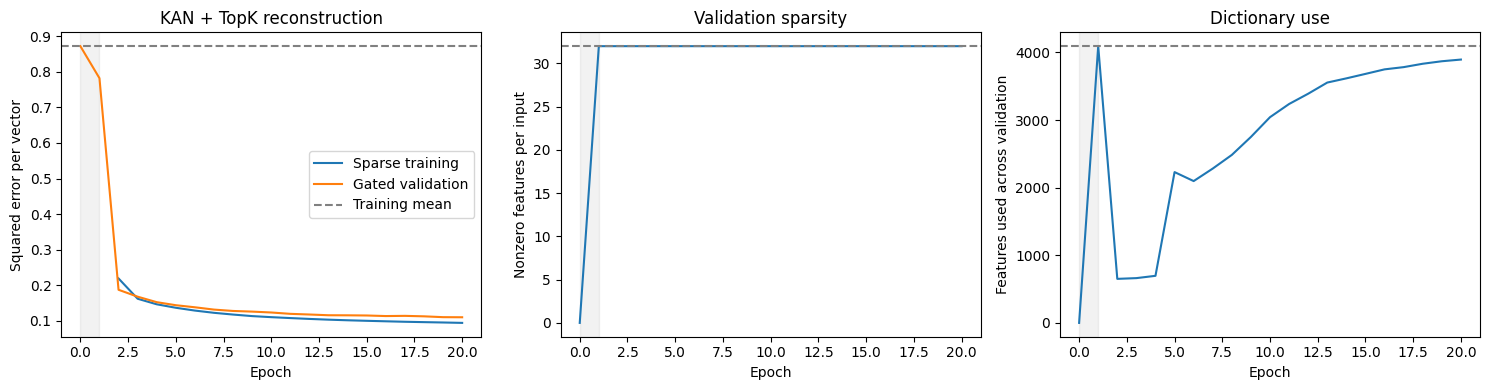

,best_epoch,model_type,k_active,warmup_epochs,validation_dates,activity_threshold,validation_error,mean_baseline_error,fraction_variance_unexplained,validation_l1,mean_active_features,max_active_features,mean_active_above_threshold,features_used_on_validation,validation_clamped_fraction,selected_clamped_fraction
0,20,kan_topk,32,1,"[2017-08-29, 2018-04-29, 2018-12-29]",0.000001,0.110088,0.872172,0.126223,2.985299,32.0,32,32.0,3894,0.167372,0.007921


Best model: /content/drive/MyDrive/AMS691_GraphCast/monthly_2017_2018/kan_topk_runs/kan_topk_k32/best.pt
History: /content/drive/MyDrive/AMS691_GraphCast/monthly_2017_2018/kan_topk_runs/kan_topk_k32/history.csv
Next: notebook 04 with SAE_TYPE="kan_topk", SAE_RUN="kan_topk_k32".


In [6]:
# @title Show results and load the best sparse model
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sae_checkpoint import load_model
summary = trainer.summarize()
trainer.plot_history()
plt.show()
display(pd.DataFrame([summary]))
assert summary['max_active_features'] <= K_ACTIVE
best = torch.load(RUN_DIR / 'best.pt', map_location='cpu', weights_only=True)
model = load_model(best, device).eval()
print('Best model:', RUN_DIR / 'best.pt')
print('History:', RUN_DIR / 'history.csv')
print(f'Next: notebook 04 with SAE_TYPE="kan_topk", SAE_RUN="{RUN_NAME}".')
if summary['fraction_variance_unexplained'] is not None and summary['fraction_variance_unexplained'] >= 1:
    print('This model has not beaten the training-mean reconstruction baseline yet.')


Next, open [notebook 04](https://colab.research.google.com/github/observerhan/graphcast-interpretability/blob/kan-topk-training/04_probe_topk_cyclones.ipynb), then optionally [notebook 05](https://colab.research.google.com/github/observerhan/graphcast-interpretability/blob/kan-topk-training/05_plot_cyclone_features.ipynb). Both default to `SAE_TYPE='kan_topk'` and run `kan_topk_k32` on this branch. Use your custom run name if you changed it here.

Reuse the labeled activations and storm cache already saved by notebooks 03 and 05. Both TopK models use sparse feature storage in notebook 04, while retaining KAN's negative values.

Compare validation F1 on the same cyclone dates before choosing settings; the 2021 test result is for final reporting. The existing TopK result is a reference, not a guaranteed target. Training budget, signed codes, spline nonlinearity, warm-up and sparsity mechanism differ, so this is an exploratory comparison. See [the experiment guide](https://github.com/observerhan/graphcast-interpretability/blob/kan-topk-training/docs/kan_topk.md).
